# Frozen-recipe comparison with pooled cross-validation

We compared **20 recipes** using three separate measurements: the primary training-only CV, supplementary pooled train-plus-validation CV, and each original training-only fit's recorded validation score. No hyperparameters, feature choices, thresholds or model combinations were retuned during this comparison.

The retained hybrid scores **0.910474 training-only CV**, **0.892293 pooled CV**, and **0.912393 original validation F1**. Its ranks by these point estimates are **13, 8, and 1**, respectively. Tied scores share a rank.

The saved model and submission remain unchanged. The original validation score describes the original model trained without validation labels. It is not a holdout score for any pooled-fold model. No final model was fitted on all 235 labels and no Kaggle score was measured.

In [1]:
from pathlib import Path
import json,pandas as pd,numpy as np
import matplotlib.pyplot as plt
root=Path.cwd();pooled=root/'experiments/pooled_benchmark_v1'
table=pd.read_csv(pooled/'comparison.csv')
table[['candidate','training_cv_mean','training_cv_std','pooled_cv_mean','pooled_cv_std','original_validation_f1']].sort_values('pooled_cv_mean',ascending=False)

,candidate,training_cv_mean,training_cv_std,pooled_cv_mean,pooled_cv_std,original_validation_f1
11,Classical tri-training,0.912243,0.008896,0.899385,0.006379,0.903846
13,Local SVM specialist hybrid,0.920028,0.007006,0.898818,0.007535,0.905983
12,Metadata co-training hybrid,0.917905,0.003609,0.897636,0.003343,0.901709
4,Other subgroups,0.914367,0.003044,0.896454,0.001532,0.897436
15,Uniform pseudo-weight hybrid,0.909413,0.002002,0.894279,0.003850,0.903846
6,Unlabeled-subsample SVM ensemble,0.907289,0.017103,0.893617,0.007045,0.910256
8,Cluster SVM at threshold 0.60,0.907289,0.011279,0.892671,0.006379,0.901709
0,Current best hybrid,0.910474,0.007372,0.892293,0.004681,0.912393
9,Year-weighted SVM,0.912243,0.010158,0.892199,0.004012,0.905983
1,Previous cluster-guided SVM,0.907289,0.008725,0.891726,0.005943,0.910256


## Cohort and fixed settings

The comparison cohort was frozen before the pooled results were computed. It contains the five existing common-benchmark recipes plus every distinct inductive recipe with previously recorded validation sample-wise F1 of at least 0.900. Exact configuration/decision-rule duplicates were removed. Twenty recipes remain; some similar recipes can still make identical predictions.

Clustering and classification families, feature selections, regularization settings, pseudo-labeling rules, random seeds and decoding thresholds remain unchanged. Each fold trains a fresh instance. Learned coefficients, scaler statistics, cluster locations and provisional labels can change because the training rows change. Thus CV tests the fixed training recipe, not a single saved fitted object.

Existing internal calibration steps still fit only within their outer training fold, using their frozen settings. The Other subclass algorithm can reduce its requested cluster count if its pre-existing minimum-support rule requires it; that rule is unchanged. There is no new hyperparameter search.

## The three measurements

| Measurement | Gold labels available for splitting | Fitting and scoring |
|---|---:|---|
| Primary training-only CV | 157 | Same saved grouped five-fold splits and three seeds for every recipe; score complete out-of-fold predictions. |
| Supplementary pooled CV | 235 | Combine the 157 original training labels and 78 original validation labels; create a separate saved grouped five-fold partition for each of the same three seeds. |
| Original validation F1 | 157 for fitting, 78 held out | Reuse each unchanged recipe's already recorded score from its training-only fit. |

Both CV protocols use seeds 20261126–20261128. The actual fold memberships differ because the sample pools differ. Pair model differences within a protocol; matching seed numbers do not make the training-only and pooled estimates paired evaluations of the same held-out rows.

For each CV repeat, sample-wise F1 is calculated over the complete OOF matrix, weighting trials equally. The headline is the mean of those three repeat scores. Their standard deviation describes sensitivity to the partition; it is not a confidence interval.

In [2]:
protocol=json.loads((pooled/'protocol.json').read_text())
folds=pd.DataFrame([{k:f[k] for k in ['seed','fold','training_gold_rows','heldout_gold_rows','original_validation_rows_in_training','original_validation_rows_heldout','masked_duplicates_excluded']} for f in protocol['folds']])
folds

,seed,fold,training_gold_rows,heldout_gold_rows,original_validation_rows_in_training,original_validation_rows_heldout,masked_duplicates_excluded
0,20261126,0,183,52,61,17,72
1,20261126,1,193,42,59,19,5
2,20261126,2,190,45,64,14,87
3,20261126,3,185,50,64,14,20
4,20261126,4,189,46,64,14,17
5,20261127,0,189,46,64,14,8
6,20261127,1,190,45,62,16,69
7,20261127,2,190,45,64,14,36
8,20261127,3,188,47,62,16,17
9,20261127,4,183,52,60,18,71


## Grouping, fitting boundaries and input preservation

The combined pool contains 235 gold rows in 222 unique embedding groups, plus the same 1,014 originally masked training examples. Identical embedding groups never cross an outer fold boundary. Masked examples matching a held-out group's embedding are excluded from that training fold. The observed gold duplicates have no conflicting reason labels.

Scaling, PCA, clusters, classifiers and pseudo-labeling fit only the current outer training gold and permitted masked rows. Rows originally belonging to validation can supply labels only when assigned to the training portion of that pooled fold. Held-out inputs do not participate in fitting. Kaggle test features are not used.

The pooled script creates an isolated in-memory dataset context and restores the original engine afterward. It does not modify either original CSV, the saved current-best configuration, any current prediction file or the primary CV fold assignments. Hash checks verify those boundaries. The current-model and nested-calibration paths also pass held-out-label perturbation and query-batch invariance tests in the enlarged data context.

In [3]:
conclusions=json.loads((pooled/'conclusions.json').read_text())
conclusions

{'model_count': 20,
 'leaders': {'training_cv_mean': ['Local SVM specialist hybrid'],
  'pooled_cv_mean': ['Classical tri-training'],
  'original_validation_f1': ['Current best hybrid']},
 'current': {'training_cv_mean': 0.910474168435952,
  'pooled_cv_mean': 0.8922931442080378,
  'original_validation_f1': 0.9123931623931625},
 'current_ranks': {'training_cv_mean': 13,
  'pooled_cv_mean': 8,
  'original_validation_f1': 1},
 'current_leads_all_three': False,
 'current_submission_changed': False,
 'full_train_plus_validation_refit': False,
 'interpretation': 'Point-estimate ranks on overlapping development data, not significance tests or three independent tests.'}

In [4]:
summary=json.loads((pooled/'summary.json').read_text())
rows=[]
for r in summary['models']:
    result=json.loads((pooled/(r['pooled_result_key']+'.json')).read_text())
    for seed,m in zip(summary['seeds'],result['repeat_scores']):
        rows.append(dict(candidate=r['candidate'],seed=seed,F1=m['sample_f1']))
pd.DataFrame(rows).pivot(index='candidate',columns='seed',values='F1')

seed,20261126,20261127,20261128
candidate,,,
Classical tri-training,0.899858,0.891348,0.906950
Cluster SVM at threshold 0.60,0.885106,0.892199,0.900709
Current best hybrid,0.887092,0.891348,0.898440
Drug-target augmented SVM,0.882270,0.889362,0.902128
Earlier low-density SVM,0.882270,0.889362,0.902128
Embedding-kernel SVM,0.882270,0.889362,0.902128
Graph-regularized SVM,0.874326,0.892199,0.880851
Kernel-committee reason hybrid,0.885816,0.890780,0.893617
Label-frequency correction,0.889362,0.888652,0.892199


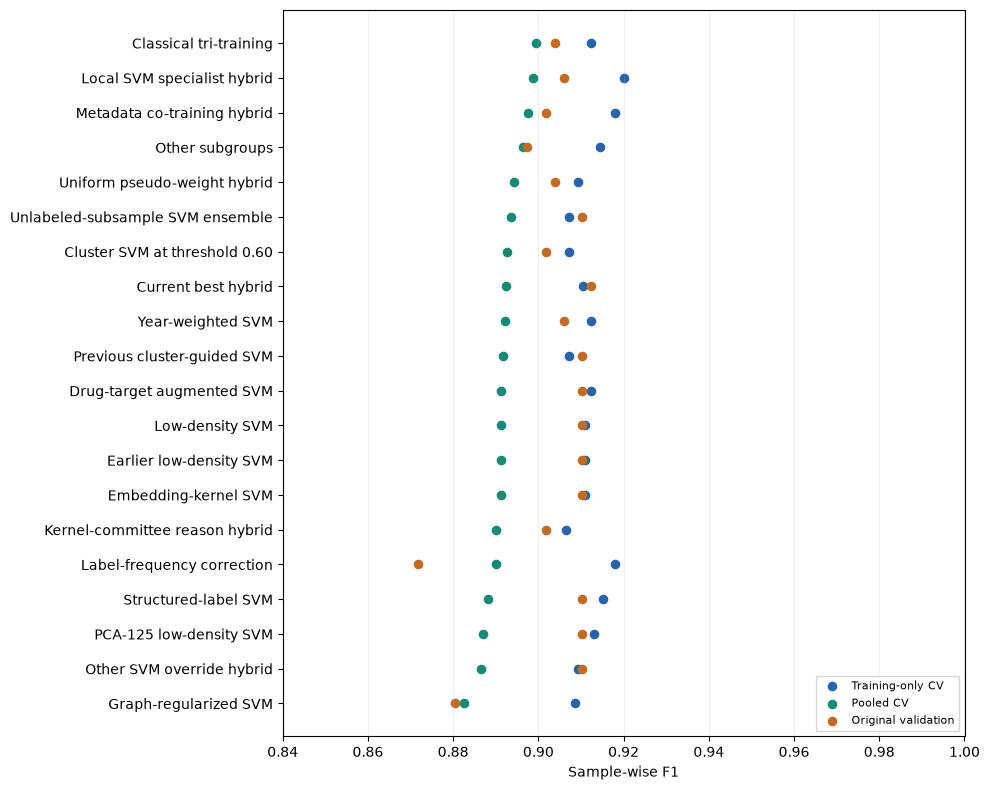

In [5]:
plot=table.sort_values('pooled_cv_mean')
y=np.arange(len(plot));fig,ax=plt.subplots(figsize=(10,8))
for col,label,color in [('training_cv_mean','Training-only CV','#2864aa'),('pooled_cv_mean','Pooled CV','#188977'),('original_validation_f1','Original validation','#c46b23')]:
    ax.scatter(plot[col],y,label=label,color=color,s=35)
ax.set(yticks=y,yticklabels=plot.candidate,xlabel='Sample-wise F1',xlim=(min(.84,float(plot[['training_cv_mean','pooled_cv_mean','original_validation_f1']].min().min())-.01),1.0))
ax.grid(axis='x',alpha=.2);ax.legend(loc='lower right',fontsize=8)
fig.tight_layout();fig.savefig(root/'figures/current_pooled_benchmark.png',dpi=180)
plt.show()

## Interpreting the rankings

These are three complementary measurements on overlapping data, not three independent tests. Pooled CV uses a larger labeled training sample in each fold and a different mixture of labeled examples. A higher pooled score therefore cannot be attributed solely to larger held-out folds, and it is not a remeasurement of the exact saved model.

Prior development already used training labels and repeatedly consulted validation. Freezing recipes and common folds improves comparability but does not erase that selection history. The later-year Kaggle population can still differ from both labeled pools. Small rank differences should not be treated as established superiority, especially with only three dependent repeats.

The cohort and all settings were frozen before this comparison. Point-estimate leaders are reported explicitly; no recipe is automatically promoted just for topping one column. The primary training-only protocol remains the standard for future comparisons. The final all-label refit remains deferred.

## Why pooled CV need not score higher

More training labels do not guarantee a higher measured score. Pooled CV changes both the training sample and the population being scored, while keeping the algorithm settings fixed. It also applies the same strict duplicate-group exclusion rule to the original validation rows: matching masked training rows are removed when their group is held out. The original standalone validation fit used all supplied training rows, which included some unlabeled examples with identical embeddings.

The diagnostics below quantify those differences for the retained recipe. The source-specific pooled OOF scores are descriptive subsets of the same CV run; neither is a new independent validation result. These observations do not establish which factor caused the score change.

In [6]:
json.loads((pooled/'population-diagnostics.json').read_text())

{'current_pooled_oof_original_training_rows': 0.8968152866242037,
 'current_pooled_oof_original_validation_rows': 0.8831908831908831,
 'original_validation_rows_matching_masked_training_embeddings': 20,
 'original_validation_rows_matching_gold_training_embeddings': 0,
 'interpretation': 'Subset OOF diagnostics, not separate holdout scores. Group CV excludes matching masked rows; the original training-only full fit legitimately used all provided training rows. This difference is not established as the cause of a score change.'}

In [7]:
json.loads((pooled/'integrity.json').read_text())

{'passed': True,
 'runner_sha256': 'fed9b6d81ad85d17529e09fa1dace0a72a086d40e7edca9750fe46e9105f3e2b',
 'pooled_gold_rows': 235,
 'gold_embedding_groups': 222,
 'no_conflicting_gold_embedding_groups': True,
 'checks': [{'model': 'Current best hybrid',
   'heldout_labels_cannot_change_predictions': True,
   'query_batch_invariance': True},
  {'model': 'Label-frequency correction',
   'heldout_labels_cannot_change_predictions': True,
   'query_batch_invariance': True}],
 'folds_verified': True,
 'all_configs_and_rules_unchanged': True}

In [8]:
preservation=json.loads((pooled/'preservation.json').read_text())
{k:v for k,v in preservation.items() if k!='protected_sha256'}

{'raw_inputs_and_current_model_unchanged': True,
 'primary_folds_unchanged': True,
 'original_engine_context_restored': True}

## Reproduction

Run `.venv/bin/python benchmark_cv.py` for the primary comparison and `.venv/bin/python benchmark_pooled_cv.py` for the separate pooled comparison. Saved results are reused only when the protocol, recipe, decoder and source hashes match. `--verify-only` checks pooled fold and recipe consistency; `--integrity-only` checks fitting boundaries without running the full cohort.

The cohort snapshot, exact configurations, source hashes, complete OOF predictions, fold memberships and per-fold metrics are included under `experiments/benchmark_v1` and `experiments/pooled_benchmark_v1`. Notebook 04 embeds the source files. Historical validation measurements retain their source filenames in the frozen registries.